In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [25]:
# ---------- 1. Load and inspect ----------
df = pd.read_csv("Diwali_Dashboard_2.csv")
print("Shape:", df.shape)
print(df.head())
print(df.dtypes)

Shape: (15000, 14)
    Order_ID        Date Customer_ID Product_Category  Product_Name  Quantity  \
0  ORD100000  2025-01-25    CUST2796   Home & Kitchen  Cookware Set         2   
1  ORD100001  2025-08-28    CUST9669           Beauty    Hair Dryer         1   
2  ORD100002  2025-02-27    CUST5808      Electronics        Tablet         3   
3  ORD100003  2025-02-24    CUST5889      Electronics    Headphones         5   
4  ORD100004  2025-06-15    CUST9005         Clothing         Saree         5   

   Unit_Price_INR  Total_Sales_INR    Payment_Method Delivery_Status  \
0        25574.41         51148.82       Credit Card        Returned   
1        19361.41         19361.41        Debit Card        Returned   
2        38476.22        115428.66  Cash on Delivery       Delivered   
3        38145.72        190728.60       Credit Card       Delivered   
4        45940.98        229704.90               UPI       Delivered   

   Review_Rating         Review_Text      State Country  
0  

In [23]:
# ---------- 2. Cleaning and validation ----------
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

calc = df["Quantity"] * df["Unit_Price_INR"]
print("Total_Sales matches Quantity x Unit Price:", f"{((calc - df['Total_Sales_INR']).abs() < 0.5).mean() * 100:.1f}%")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

Missing values: 0
Duplicate rows: 0
Duplicate Order IDs: 0
Total_Sales matches Quantity x Unit Price: 100.0%
Date range: 2025-01-01 to 2025-12-31


In [26]:
# ---------- 3. KPIs ----------
total_revenue = df["Total_Sales_INR"].sum()
print(f"Total revenue      : Rs {total_revenue / 1e7:,.1f} Cr")
print(f"Total orders       : {len(df):,}")
print(f"Unique customers   : {df['Customer_ID'].nunique():,}")
print(f"Average order value: Rs {df['Total_Sales_INR'].mean():,.0f}")
print(f"States covered     : {df['State'].nunique()}")
print(f"Average rating     : {df['Review_Rating'].mean():.2f}")

Total revenue      : Rs 111.8 Cr
Total orders       : 15,000
Unique customers   : 7,259
Average order value: Rs 74,544
States covered     : 28
Average rating     : 3.04


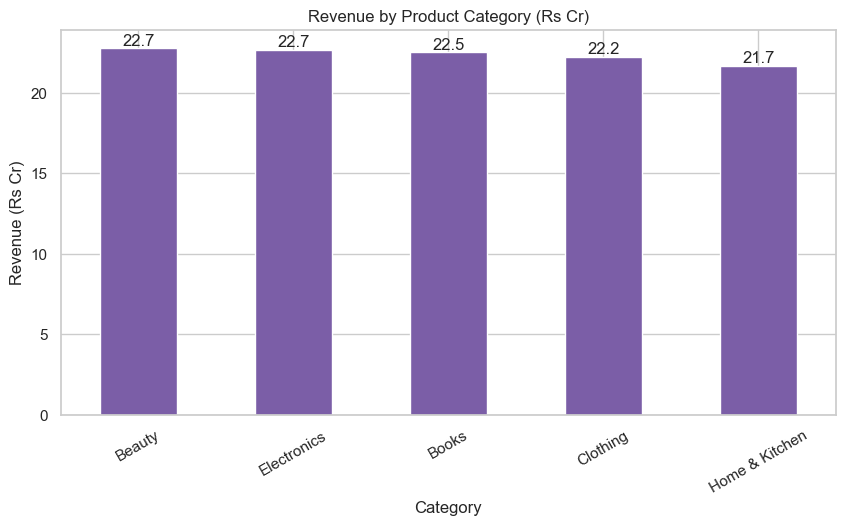

In [27]:
# ---------- 4. Revenue by category ----------
category_sales = df.groupby("Product_Category")["Total_Sales_INR"].sum().sort_values(ascending=False) / 1e7
ax = category_sales.plot(kind="bar", color="#7B5EA7")
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.title("Revenue by Product Category (Rs Cr)")
plt.xlabel("Category"); plt.ylabel("Revenue (Rs Cr)")
plt.xticks(rotation=30)
plt.show()


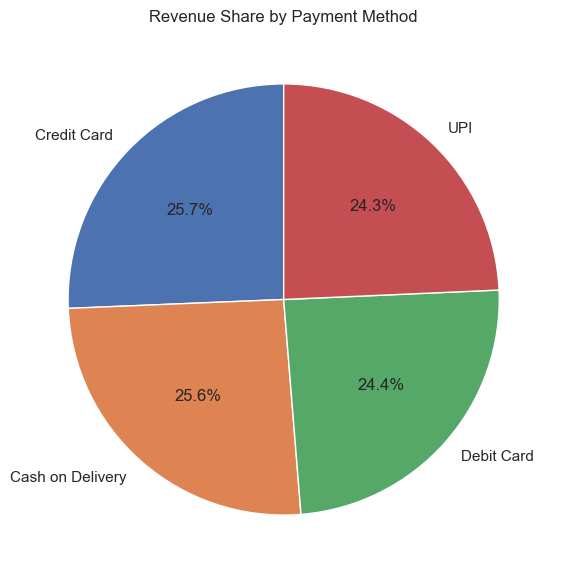

In [28]:
# ---------- 5. Revenue by payment method ----------
payment_sales = df.groupby("Payment_Method")["Total_Sales_INR"].sum().sort_values(ascending=False) / 1e7
plt.figure(figsize=(7, 7))
plt.pie(payment_sales, labels=payment_sales.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share by Payment Method")
plt.show()


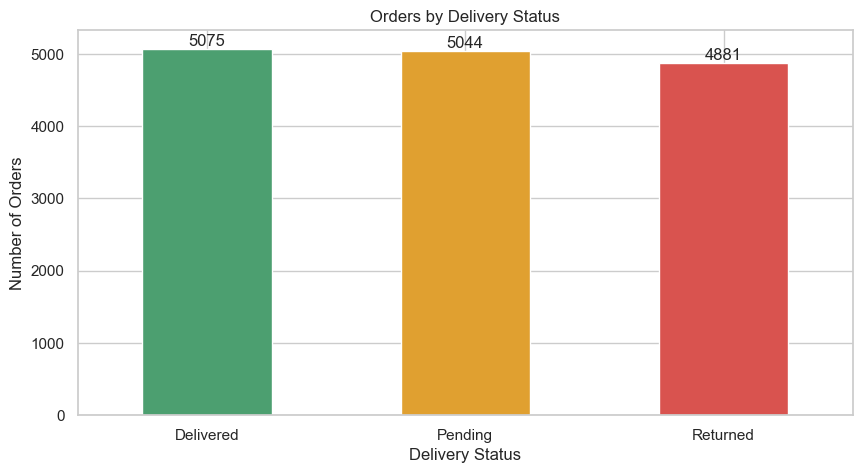

Delivery_Status
Delivered    33.8 %
Pending      33.6 %
Returned     32.5 %
Name: count, dtype: str


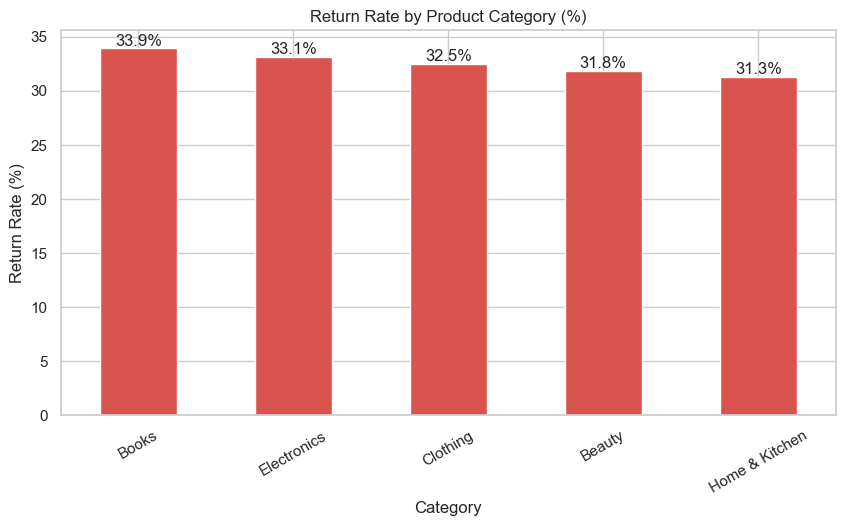

In [29]:
# ---------- 6. Delivery status and return rate ----------
status = df["Delivery_Status"].value_counts()
ax = status.plot(kind="bar", color=["#4C9F70", "#E0A030", "#D9534F"])
ax.bar_label(ax.containers[0])
plt.title("Orders by Delivery Status")
plt.xlabel("Delivery Status"); plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.show()
print((status / status.sum() * 100).round(1).astype(str) + " %")

return_rate = (df.assign(Returned=df["Delivery_Status"].eq("Returned"))
                 .groupby("Product_Category")["Returned"].mean() * 100).sort_values(ascending=False)
ax = return_rate.plot(kind="bar", color="#D9534F")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Return Rate by Product Category (%)")
plt.xlabel("Category"); plt.ylabel("Return Rate (%)")
plt.xticks(rotation=30)
plt.show()

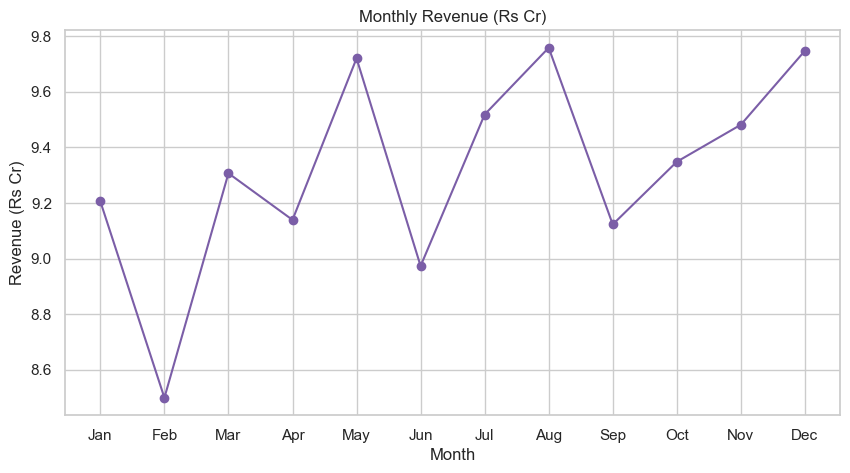

Highest month: Aug (Rs 9.76 Cr)
Lowest month : Feb (Rs 8.50 Cr)


In [34]:
# ---------- 7. Monthly revenue trend ----------
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")
monthly = df.groupby(["Month", "Month_Name"])["Total_Sales_INR"].sum().reset_index()
monthly["Revenue_Cr"] = monthly["Total_Sales_INR"] / 1e7
plt.plot(monthly["Month_Name"], monthly["Revenue_Cr"], marker="o", color="#7B5EA7")
plt.title("Monthly Revenue (Rs Cr)")
plt.xlabel("Month"); plt.ylabel("Revenue (Rs Cr)")
plt.grid(True)
plt.show()
best = monthly.loc[monthly["Revenue_Cr"].idxmax()]
worst = monthly.loc[monthly["Revenue_Cr"].idxmin()]
print(f"Highest month: {best['Month_Name']} (Rs {best['Revenue_Cr']:.2f} Cr)")
print(f"Lowest month : {worst['Month_Name']} (Rs {worst['Revenue_Cr']:.2f} Cr)")

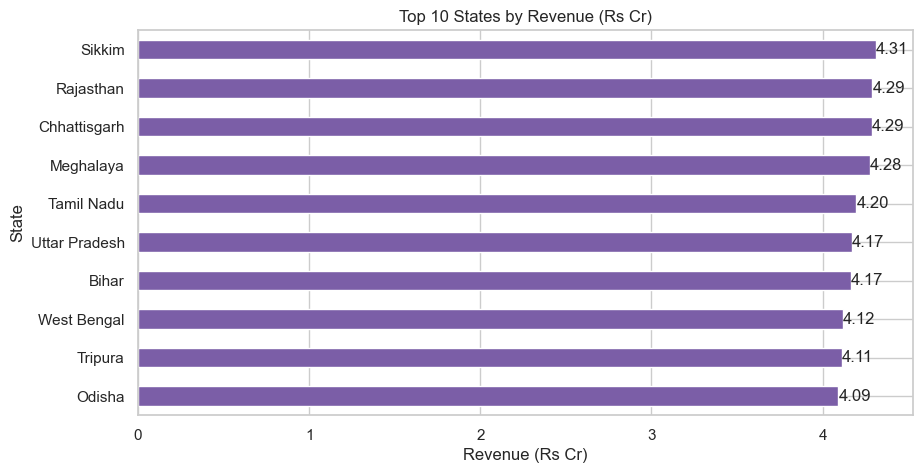

In [31]:
# ---------- 8. Top 10 states ----------
state_sales = (df.groupby("State")["Total_Sales_INR"].sum().sort_values(ascending=False) / 1e7).head(10)
ax = state_sales.sort_values().plot(kind="barh", color="#7B5EA7")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Top 10 States by Revenue (Rs Cr)")
plt.xlabel("Revenue (Rs Cr)"); plt.ylabel("State")
plt.show()

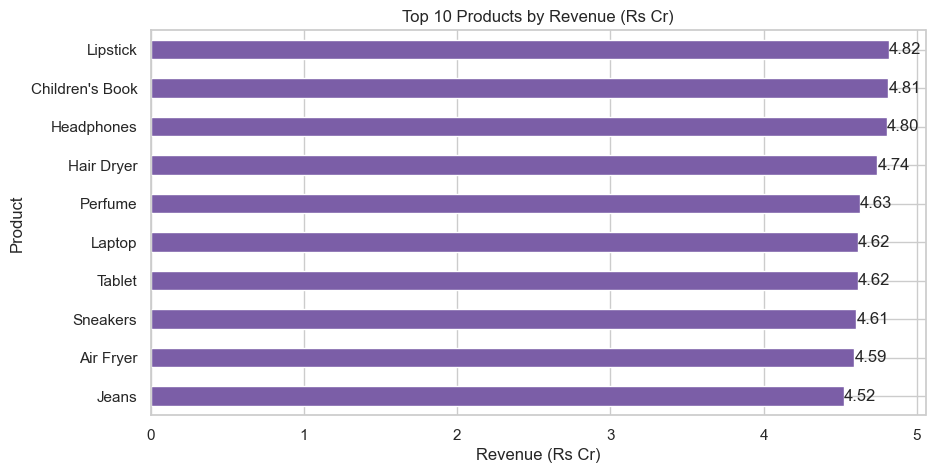

In [32]:
# ---------- 9. Top 10 products ----------
product_sales = (df.groupby("Product_Name")["Total_Sales_INR"].sum().sort_values(ascending=False) / 1e7).head(10)
ax = product_sales.sort_values().plot(kind="barh", color="#7B5EA7")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Top 10 Products by Revenue (Rs Cr)")
plt.xlabel("Revenue (Rs Cr)"); plt.ylabel("Product")
plt.show()


Product_Category
Beauty            3.04
Books             3.03
Clothing          3.00
Electronics       3.07
Home & Kitchen    3.06
Name: Review_Rating, dtype: float64
Delivery_Status
Delivered    3.00
Pending      3.06
Returned     3.06
Name: Review_Rating, dtype: float64


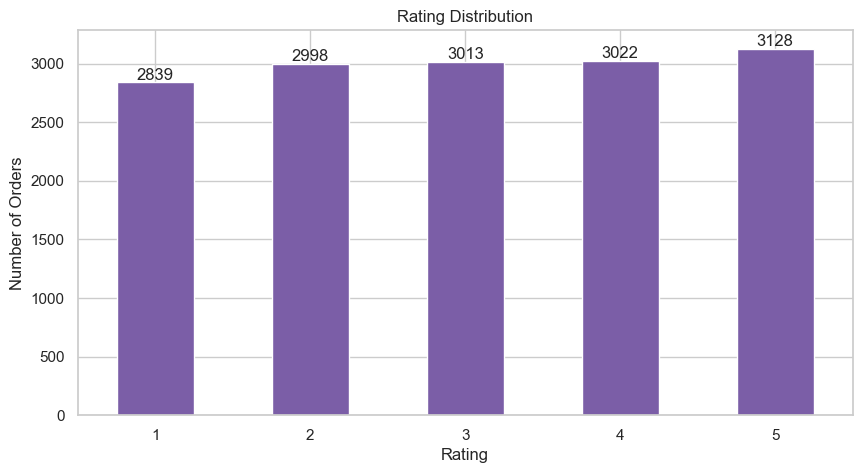

In [33]:
# ---------- 10. Ratings ----------
print(df.groupby("Product_Category")["Review_Rating"].mean().round(2))
print(df.groupby("Delivery_Status")["Review_Rating"].mean().round(2))
ax = df["Review_Rating"].value_counts().sort_index().plot(kind="bar", color="#7B5EA7")
ax.bar_label(ax.containers[0])
plt.title("Rating Distribution")
plt.xlabel("Rating"); plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.show()